# 17 · 前端 Web 实战（Tlias 案例：员工管理）

来源：[飞书讲义《17-前端Web实战(Tlias案例-员工管理)》](https://heuqqdmbyk.feishu.cn/wiki/EcwTwtRbrirIShkDB8kcRS7yndH)。本章在 Vue、TypeScript 和 ElementPlus 基础上，完成 Tlias 智能学习辅助系统的员工管理页面：条件分页查询、搜索表单、表格展示、新增员工，以及工作经历动态维护。

整理日期：2026-10-04。讲义中的 Vue/TypeScript 代码、接口调用、表单校验和 20 张配图按原顺序内嵌；补充内容单独标注。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 搭建员工管理页面 | ElementPlus 布局、查询区域、表格 | 页面结构清晰，控件绑定正确 |
| 2 | 实现条件分页查询 | 查询参数、分页器、接口请求 | 页码、页大小和条件变化后数据正确 |
| 3 | 编写搜索表单 | `name`、`gender`、日期范围 | 点击搜索会重置到第 1 页并重新查询 |
| 4 | 处理查询状态 | `watch`、loading、空数据和异常提示 | 条件或分页变化时不会产生脏数据 |
| 5 | 新增员工 | Dialog、基本信息、`POST` | 合法信息提交成功后刷新员工列表 |
| 6 | 维护工作经历 | 动态添加/删除表单行 | 至少保留一行，字段与后端结构一致 |
| 7 | 完成表单校验 | `el-form`、`rules`、`validate()` | 错误字段有提示，校验通过才提交 |

### 页面调用链

```text
进入员工页 -> 初始化查询条件 -> 查询接口 -> 表格渲染与分页
输入筛选条件/切换页码 -> watch 侦听 -> 组装参数 -> 重新查询
点击新增 -> 打开 Dialog -> 填写基本信息与工作经历 -> 校验 -> POST -> 关闭并刷新列表
```

在昨天的课程中，我们完成了部门管理的功能开发。 那今天呢，我们要来开发的是员工管理的功能。 我们来看一下员工管理的页面原型：

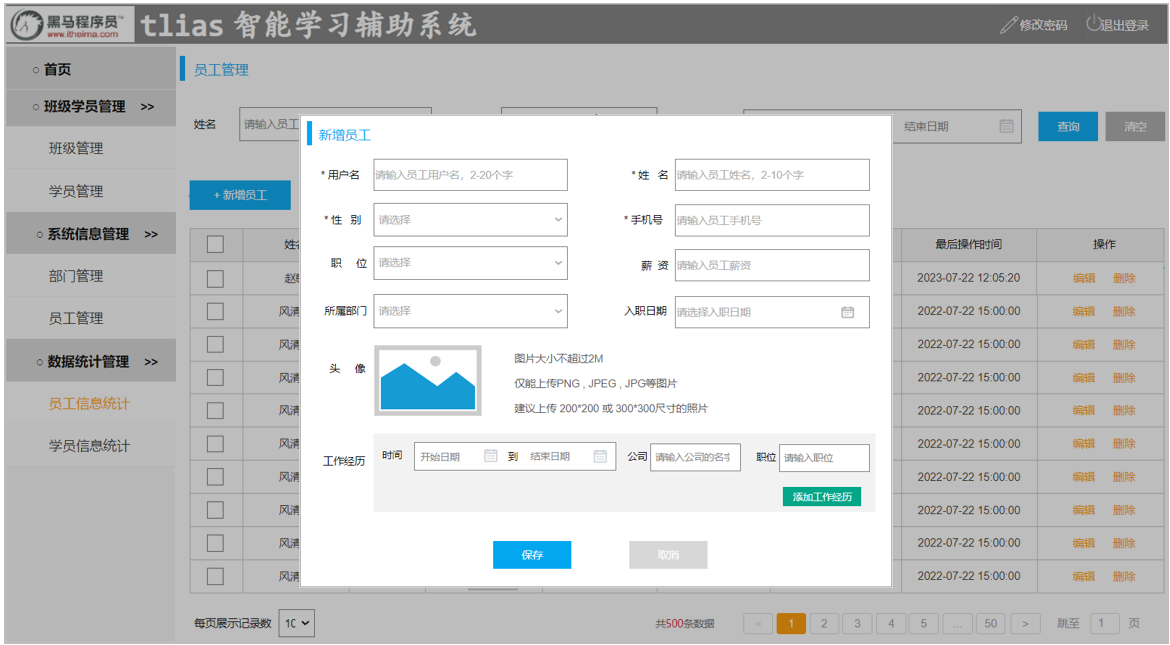

包括如下几个部分：

- 条件分页查询

- 新增员工

- 修改员工

- 删除员工

除了员工管理的功能以外，还涉及到登录、退出等功能。

## 条件分页查询

> **补充｜参数模型。** 条件分页查询通常同时包含筛选条件和分页条件。建议把 `page`、`pageSize`、`name`、`gender`、`begin`、`end` 放在一个响应式查询对象中，调用接口前再映射成后端要求的参数名，避免分页器和表单各自维护一份状态。

### 介绍

> **补充｜先确认接口契约。** 员工列表接口至少要明确查询参数、分页字段、总条数和员工数组的字段名。前端渲染前先核对真实响应结构，避免把分页对象误当数组。

在页面原型中，我们可以看到在查询员工信息列表时，既需要根据条件动态查询，还需要对查询的结果进行分页处理。

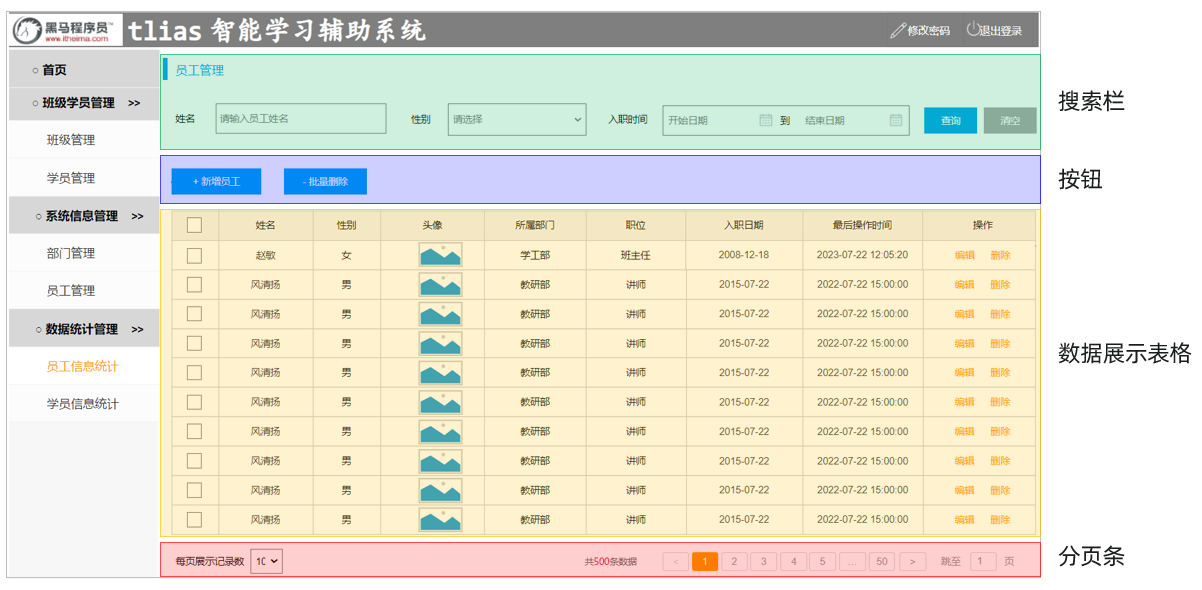

那接下来，我们在制作这个页面时，将先完成基本的页面布局，再完成数据的动态加载。 而页面布局，又分为4个部分，分别为：

- 搜索栏

- 按钮

- 数据展示表格

- 分页条

### 页面布局

> **补充｜区域拆分。** 员工页面可按“搜索栏、操作栏、表格、分页器、弹窗”划分区域。固定操作栏和表格列结构，查询状态与弹窗状态分开管理，后续维护更容易。

#### 搜索表单

> **补充｜日期范围。** 日期范围控件返回的是一个数组，提交请求前应安全解构为开始日期和结束日期；清空范围时传空值，避免把 `undefined` 或旧日期继续提交。

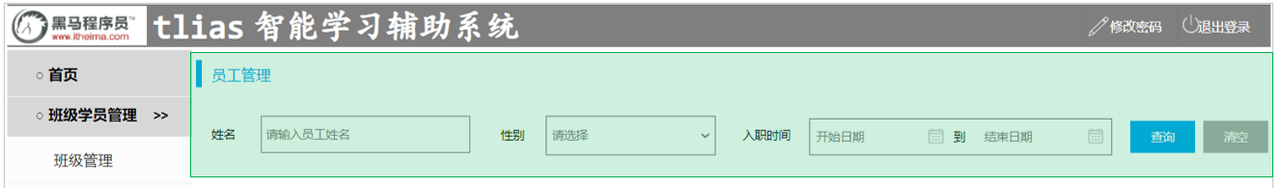

1). 在 views/emp/index.vue 中的 <script setup></script> 中增加如下js代码:

```javascript
import { ref} from 'vue'

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

const search = () => {
  // 处理查询逻辑
  console.log('Search:', searchEmp.value)
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: []
  }
  search()
}
```

2). 在 views/emp/index.vue 中的 <template></template> 中增加如下js代码:

```html
  <h1>员工管理</h1> <br>
  {{ searchEmp }}
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>
```

注意：在element-plus中，提供的日期选择组件，最终提交的值的格式，如果为 2024-02-01 这种格式，需要设置value-format属性为 YYYY-MM-DD。

我们在测试的时候，为了能够看到搜索表单采集到的数据，可以直接在通过插值表达式 {{searchEmp}} 在表单上方，将搜索表单项的值直接输出出来。

打开浏览器，我们可以看到如下页面效果：

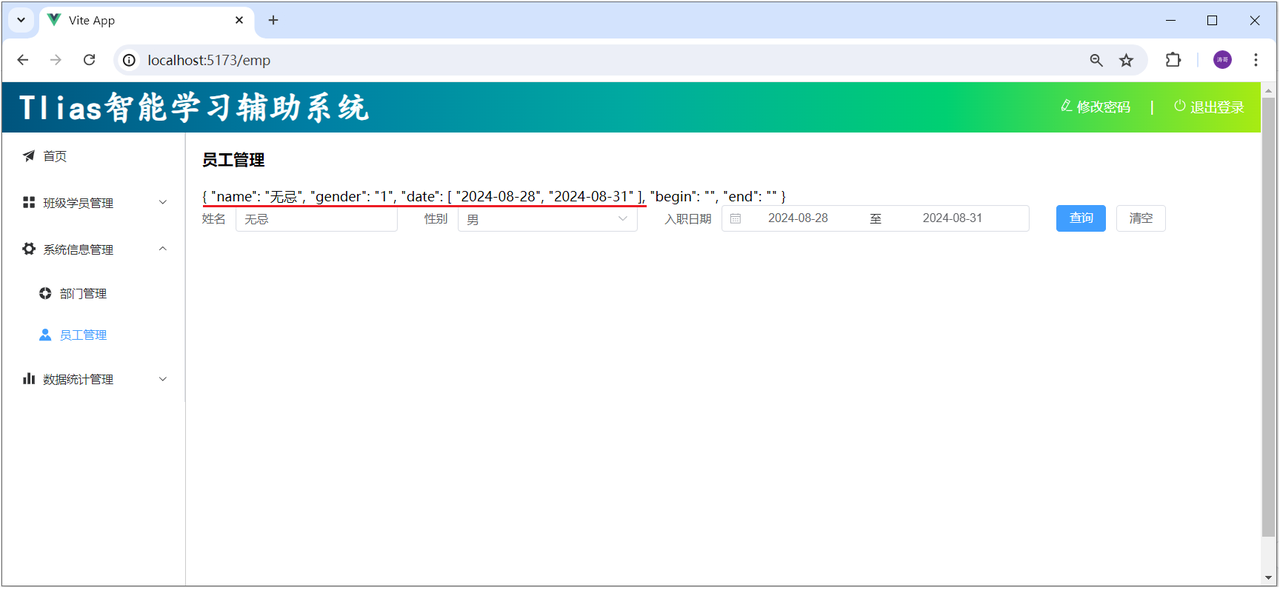

通过测试，我们可以看到，输入的入职日期的搜索条件，用的是element-plus的日期范围组件，开始时间和结束时间，两个值，是封装到了一个数组中。

而通过接口接口文档，我们可以可以看到最终在查询员工列表数据时，搜索条件中，入职日期的开始时间 和 结束时间，是两个值，一个是begin开始时间，一个是end结束时间。

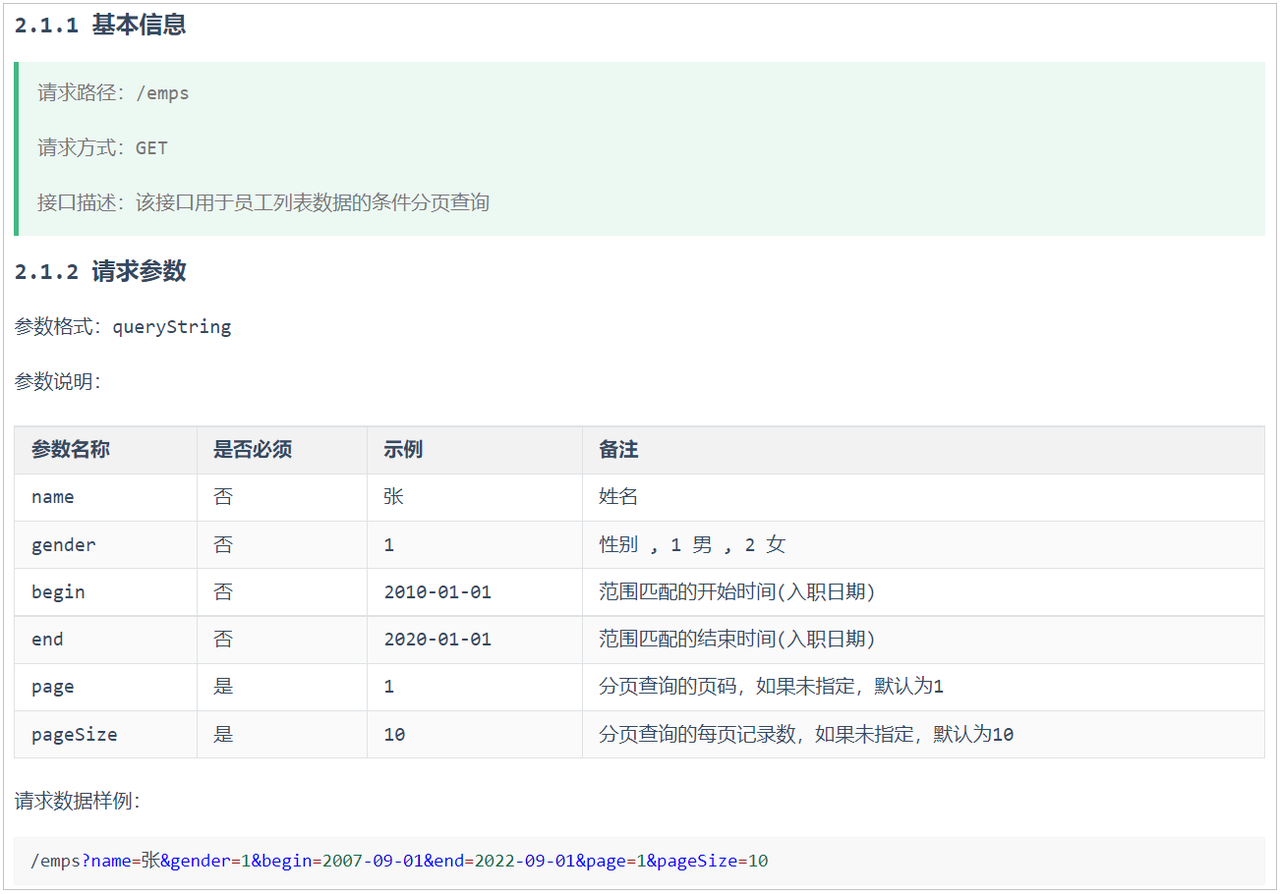

那么此时，我们就需要将searchEmp对象中的date这个数组的值，解析出来，复制给begin和end。而且，一旦date的值发生变化，我们就需要重新计算begin和end这两个时间，把数组中的第一个元素，赋值给begin；第二个元素，赋值给end。

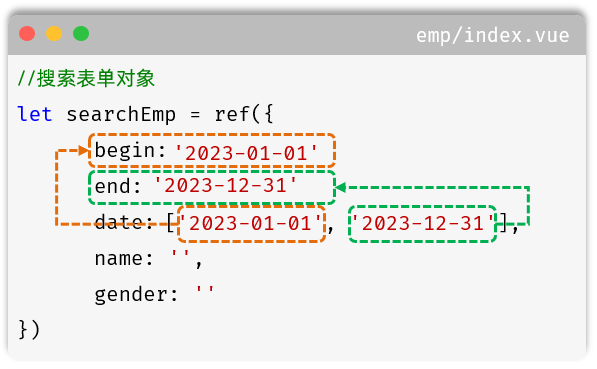

而要实现这个效果，我们就需要用到Vue3中提供的 watch 侦听。

#### watch侦听

> **补充｜避免重复请求。** 监听查询条件时要区分初始化和用户变更，并在回调中统一重置页码、组装参数和调用查询函数。不要在多个控件事件里重复写同一套请求逻辑。

- 作用：侦听一个或多个响应式数据源，并在数据源变化时调用所给的回调函数。

- 用法：

- 导入watch函数

- 执行watch函数，传入要侦听的响应式数据源（ref对象）和回调函数；

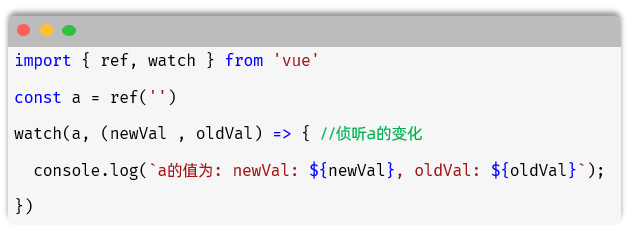

- 侦听对象的单个属性

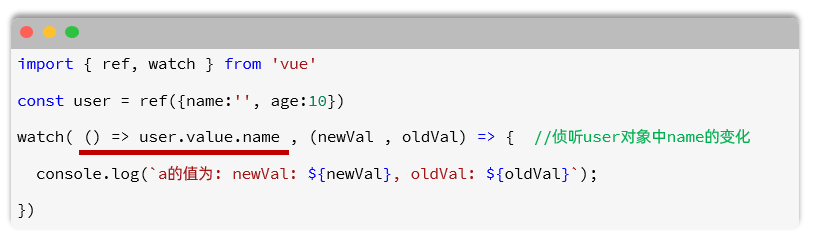

- 侦听对象的全部属性

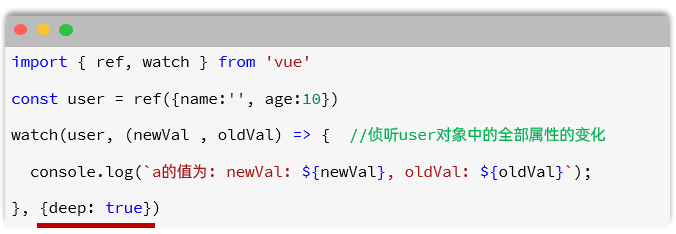

第三个可选参数，常见两个选项：

- deep（boolean）：是否深度侦听，默认浅层侦听。

- immediate（boolean）：是否在侦听创建时立即触发回调函数。

介绍完了watch侦听的基本语法之后，我们再来完成搜索栏中员工入职日期的开始时间和结束时间的处理。 我们要做到，在输入的时间发生变化时，自动为searchEmp中的begin，end两个属性赋值。

具体代码如下，在 views/emp/index.vue 文件中的 <script></script> 中增加watch监听：

```javascript
import { ref, watch } from 'vue'

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

const search= () => {
  // 处理查询逻辑
  console.log('Search:', searchEmp.value)
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}
```

#### 表格展示

> **补充｜显示与提交分离。** 表格列可以格式化性别、头像和日期，但不要修改原始对象。日期、空值和图片加载失败都应有可读的兜底显示。

接下来，我们再来制作这个表格。通过页面原型，我们可以看到表格的展示内容及展示形式：

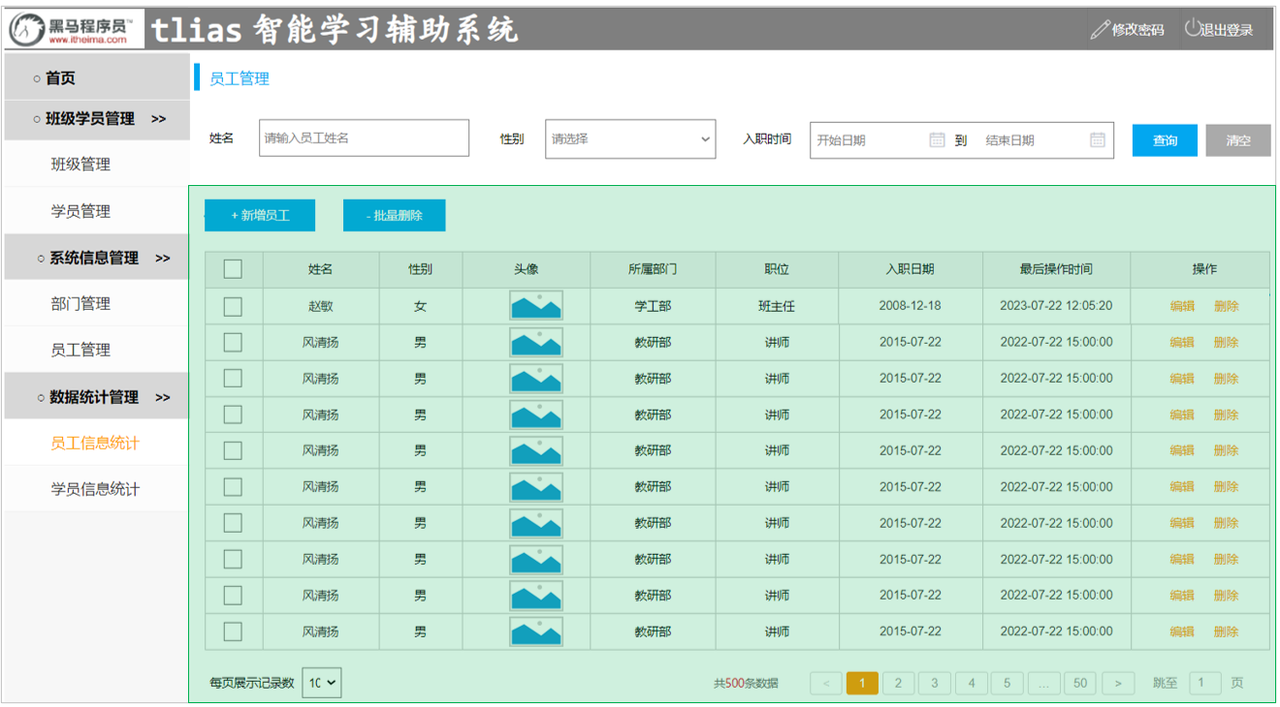

调整后如下所示（绿色背景部分为新添加部分）：

```html
<script setup>
import { ref, watch } from 'vue'

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

const search= () => {
  // 处理查询逻辑
  console.log('Search:', searchEmp.value)
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([
   {
        "id": 1,
        "username": "jinyong",
        "password": "123456",
        "name": "金庸",
        "gender": 1,
        "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2022-09-02-00-27-53B.jpg",
        "job": 2,
        "salary": 8000,
        "entryDate": "2015-01-01",
        "deptId": 2,
        "deptName": "教研部",
        "createTime": "2022-09-01T23:06:30",
        "updateTime": "2022-09-02T00:29:04"
  }
])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)

// 分页处理
const handleSizeChange = (val) => {
  search()
}
const handleCurrentChange = (val) => {
  search()
}


</script>

<template>
  <h1>员工管理</h1> <br>
  {{ searchEmp }}
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click=""> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

<!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="170" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" alt="Avatar" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
      <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
  <el-pagination
    @size-change="handleSizeChange"
    @current-change="handleCurrentChange"
    v-model:current-page="currentPage"
    v-model:page-size="pageSize"
    :page-sizes="[10, 20, 30, 40]"
    layout="total, sizes, prev, pager, next, jumper"
    :total="total"
  >
  </el-pagination>
</template>

<style scoped>
.avatar {
  height: 40px;
}
</style>
```

代码编写完毕后，我们打开浏览器会看到如下效果：

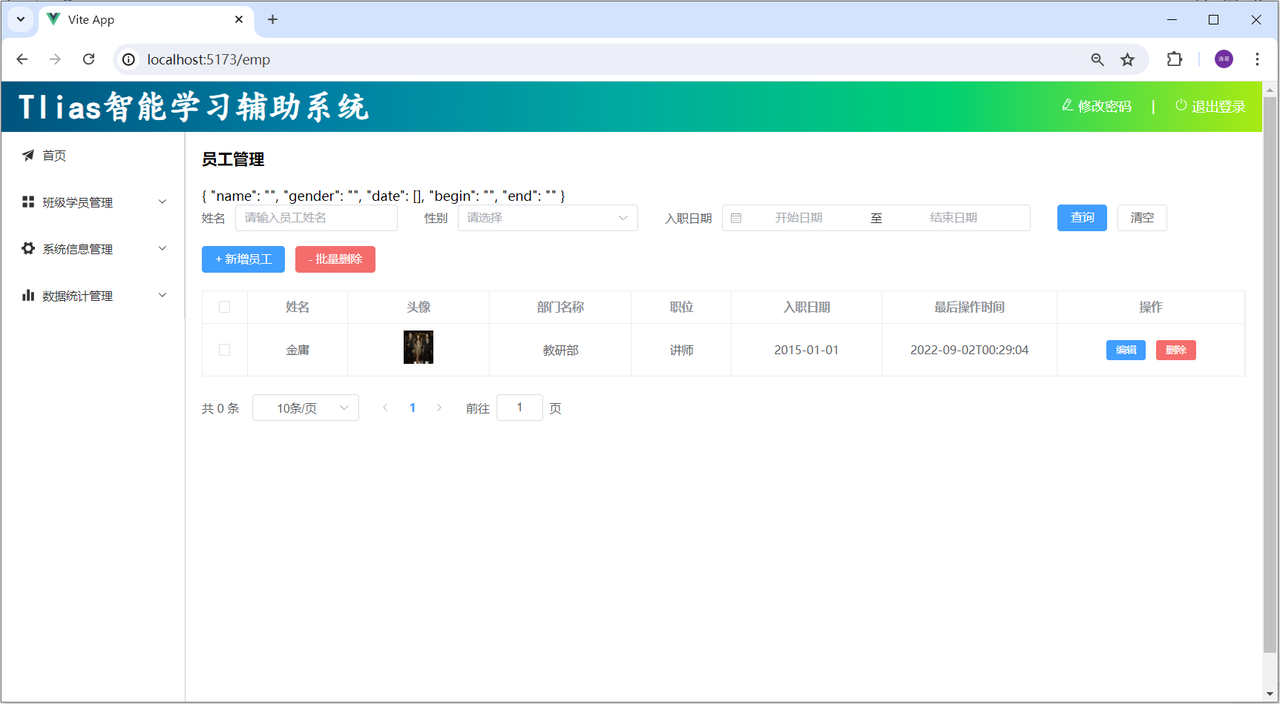

我们可以看到，图片、职位字段都正常展示出来了。

### 页面交互

> **补充｜状态反馈。** 查询、提交和弹窗关闭都要有明确的 loading、成功和失败状态。请求进行时禁用触发按钮，避免快速点击产生重复请求。

基本的页面布局完成之后，接下来，我们再来完成页面的交互效果，具体效果有如下三项：

- 页面加载完毕后，查询员工信息列表。

- 点击查询按钮，查询员工信息列表。

- 当页码、每页展示记录数发生变化时，查询员工信息列表。

那么要想实现上述的效果，我们就需要在Vue的钩子函数 onMounted 中，调用查询方法 search，然后在 search方法中发起异步请求，请求服务端。

当页码、每页展示的记录数发生变化时，会触发 handleSizeChange、handleCurrentChange 方法，然后在这两个方法中再调用 search方法，发起异步请求，请求服务端即可。

具体代码实现如下：

1). 在 src/api 目录下再定义一个 emp.js

我们可以一次性将增删改查相关的api操作的函数都定义好。

```javascript
import request from "@/utils/request";

//查询员工列表数据
export const queryPageApi = (name,gender,begin,end,page,pageSize) => 
  request.get(`/emps?name=${name}&gender=${gender}&begin=${begin}&end=${end}&page=${page}&pageSize=${pageSize}`)

//新增
export const addApi = (emp) =>  request.post('/emps', emp);

//根据ID查询
export const queryInfoApi = (id) =>  request.get(`/emps/${id}`);

//修改
export const updateApi = (emp) =>  request.put('/emps', emp);

//删除
export const deleteApi = (ids) =>  request.delete(`/emps?ids=${ids}`);
```

2). 在 src/views/emp/index.vue 文件中完成页面交互实现

```html
<script setup>
import { ref, watch, onMounted } from 'vue'
import { queryPageApi } from '@/api/emp'

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

onMounted(() => {
  search()
})

//查询员工
const search= async () => {
  console.log('Search:', searchEmp.value)
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender, searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows
    total.value = result.data.total
  }
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)

// 分页处理
const handleSizeChange = (val) => {
  search()
}
const handleCurrentChange = (val) => {
  search()
}

</script>

<template>
  <h1>员工管理</h1> <br>
  {{ searchEmp }}
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click=""> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

  <!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="80" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
      <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
      </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
  <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />
  </el-pagination>
</template>

<style scoped>
.avatar {
  height: 40px;
}
</style>
```

代码编写完成之后，我们可以打开浏览器测试一下：

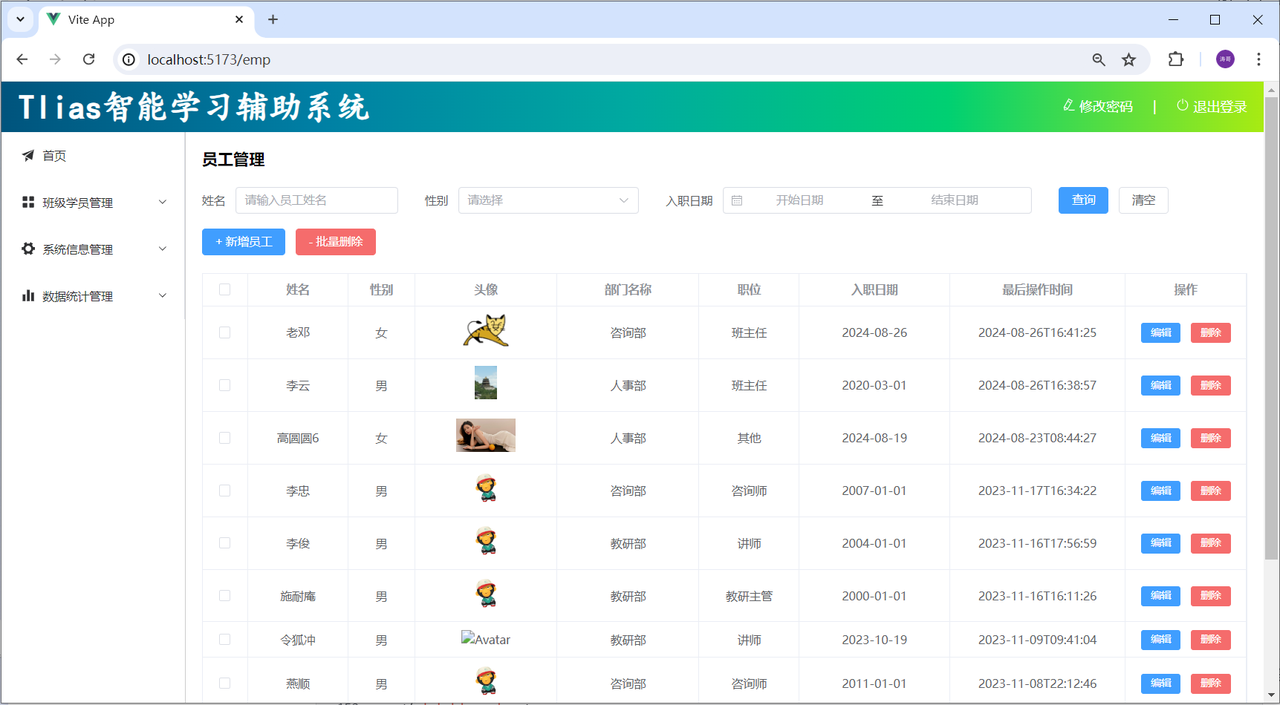

## 新增员工

> **补充｜表单初始化。** 打开新增弹窗时重置基本信息、工作经历数组和校验状态；关闭时清理旧数据。提交成功后再关闭弹窗并重新查询列表，确保总条数和分页数据同步。

### 页面布局

> **补充｜区域拆分。** 员工页面可按“搜索栏、操作栏、表格、分页器、弹窗”划分区域。固定操作栏和表格列结构，查询状态与弹窗状态分开管理，后续维护更容易。

#### 需求

> **补充｜数据边界。** 员工基本信息和工作经历是一个整体提交，字段命名、日期格式和必填约束必须与后端 DTO 保持一致。先列出最小可提交数据，再逐项增加可选字段。

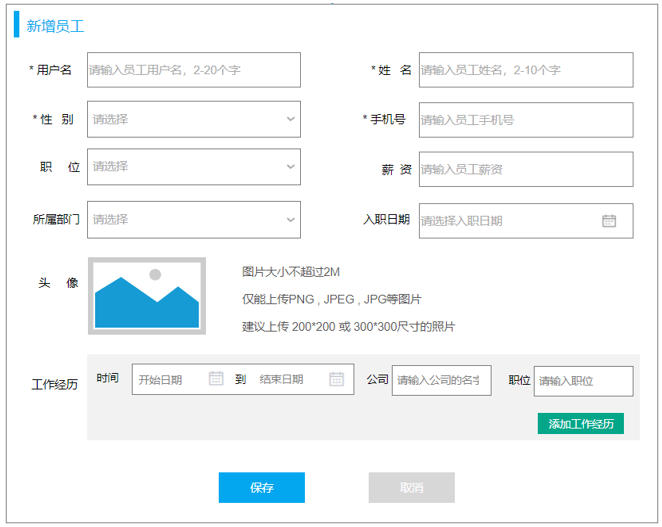

从页面原型中，我们可以看到，新增员工信息的表单包含两个部分，分别为：

- 员工的基本信息

- 员工的工作经历信息

#### 基本布局实现

> **补充｜组件职责。** 查询条件、员工表格和新增弹窗可以拆成局部组件，但查询参数和刷新方法应由页面统一协调，避免子组件各自请求同一列表。

接下来，我们也可以基于AI来帮我们完成页面的整体布局。

在 src/views/emp/index.vue 中增加如下代码（绿色背景部分）：

```html
<script setup>
import { ref, watch, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryPageApi } from '@/api/emp'

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

onMounted(() => {
  search()
})

//查询员工
const search= async () => {
  console.log('Search:', searchEmp.value)
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender, searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows
    total.value = result.data.total
  }
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)


// 分页处理
const handleSizeChange = (val) => {
  search();
}
const handleCurrentChange = (val) => {
  search();
}


//新增员工
const addEmp = () => {
  dialogVisible.value = true
  dialogTitle.value = '新增员工'
}


//新增/修改表单
const employeeFormRef = ref(null)
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

//文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response,uploadFile) => {
  employee.value.image = response.data
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

</script>

<template>
  <h1>员工管理</h1> <br>
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click="addEmp"> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

  <!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="80" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" alt="Avatar" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
      <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
      </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
    <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />

  <!-- 新增/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
      <el-form ref="employeeFormRef" :model="employee" label-width="80px">
        <!-- 基本信息 -->
        <!-- 第一行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="用户名">
              <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
            </el-form-item>
          </el-col>
          
          <el-col :span="12">
            <el-form-item label="姓名">
              <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第二行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="性别">
              <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
                <el-option label="男" value="1"></el-option>
                <el-option label="女" value="2"></el-option>
              </el-select>
            </el-form-item>
          </el-col>

          <el-col :span="12">
            <el-form-item label="手机号">
              <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第三行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="职位">
              <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
                <el-option label="班主任" value="1"></el-option>
                <el-option label="讲师" value="2"></el-option>
                <el-option label="学工主管" value="3"></el-option>
                <el-option label="教研主管" value="4"></el-option>
                <el-option label="咨询师" value="5"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="薪资">
              <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第四行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="所属部门">
              <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
                <el-option label="研发部" value="1"></el-option>
                <el-option label="市场部" value="2"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="入职日期">
              <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
        

        <!-- 工作经历 -->
        <!-- 第六行 -->
        <el-row :gutter="10">
          <el-col :span="24">
            <el-form-item label="工作经历">
              <el-button type="success" size="small" @click="">+ 添加工作经历</el-button>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第七行 ...  工作经历 -->
        <el-row :gutter="3">
          <el-col :span="10">
            <el-form-item size="small" label="时间" label-width="80px">
              <el-date-picker type="daterange" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="公司" label-width="60px">
              <el-input placeholder="请输入公司名称"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="职位" label-width="60px">
              <el-input placeholder="请输入职位"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="2">
            <el-form-item size="small" label-width="0px">
              <el-button type="danger" >- 删除</el-button>
            </el-form-item>
          </el-col>
        </el-row>
      </el-form>
      
        <!-- 底部按钮 -->
        <template #footer>
          <span class="dialog-footer">
            <el-button @click="dialogVisible = false">取消</el-button>
            <el-button type="primary" @click="">保存</el-button>
          </span>
        </template>

    </el-dialog>
    
</template>

<style scoped>
.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

代码编写完毕后，打开浏览器看到最终效果如下：

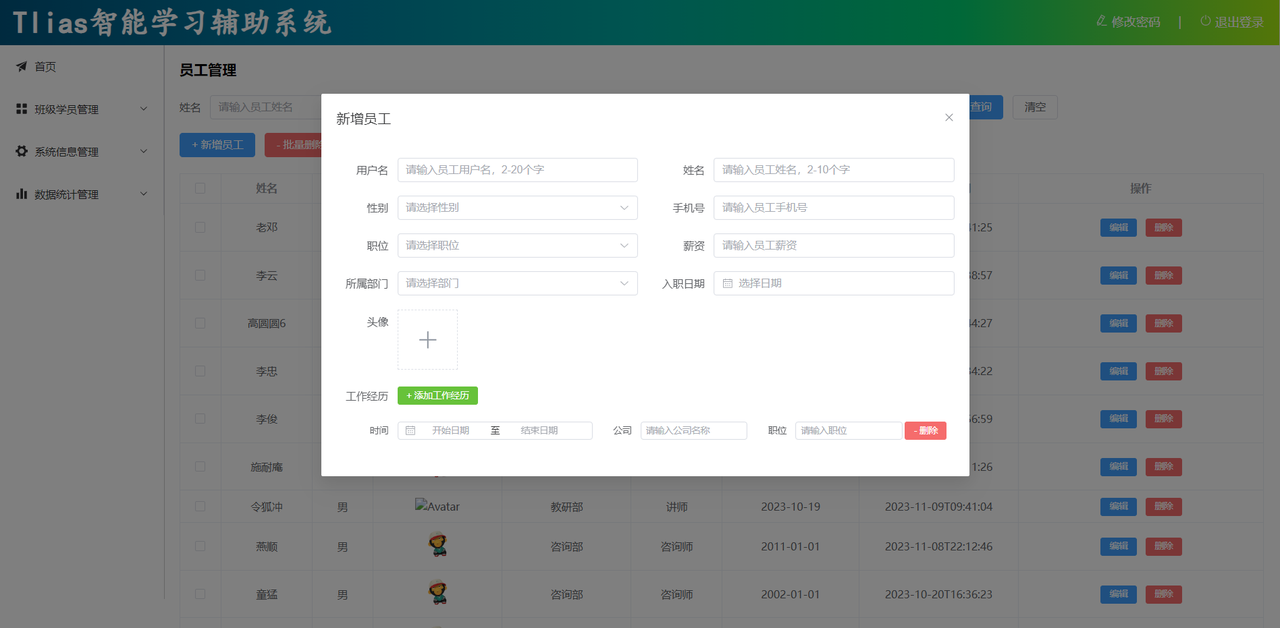

这样最基本的布局就有了，接下来，我们需要对其进行进一步的优化。

#### 页面布局优化

> **补充｜响应式布局。** 搜索项较多时使用 ElementPlus 栅格和换行布局，保证窄屏下按钮不会遮挡输入框；分页器使用稳定的容器高度，避免数据变化导致页面跳动。

表单中的数据动态展示 。比如：所属部门、职位、性别，这些源数据我们可以定义在js代码中，在页面中基于v-for指令，遍历展示出来，便于项目的统一维护处理。

优化后的页面内容如下：

```html
<script setup>
import { ref, watch, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryPageApi } from '@/api/emp'
import { queryAllApi as queryAllDeptApi } from '@/api/dept'

//职位列表数据
const jobs = ref([{ name: '班主任', value: 1 },{ name: '讲师', value: 2 },{ name: '学工主管', value: 3 },{ name: '教研主管', value: 4 },{ name: '咨询师', value: 5 },{ name: '其他', value: 6 }])
//性别列表数据
const genders = ref([{ name: '男', value: 1 }, { name: '女', value: 2 }])
//部门列表数据
const deptList = ref([])

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

onMounted(async () => {
  search()

  //加载所有部门数据
  const result = await queryAllDeptApi();
  if(result.code){
    deptList.value = result.data
  }
})

//查询员工
const search= async () => {
  console.log('Search:', searchEmp.value)
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender, searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows
    total.value = result.data.total
  }
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)


// 分页处理
const handleSizeChange = (val) => {
  search()
}
const handleCurrentChange = (val) => {
  search()
}


//新增员工
const addEmp = () => {
  dialogVisible.value = true
  dialogTitle.value = '新增员工'
}

//新增/修改表单
const employeeFormRef = ref(null)
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

//文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response,uploadFile) => {
  employee.value.image = response.data
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

</script>

<template>
  <h1>员工管理</h1> <br>
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click="addEmp"> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

  <!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="80" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" alt="Avatar" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
     <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
    <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />

  <!-- 新增/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
      <el-form ref="employeeFormRef" :model="employee" label-width="80px">
        <!-- 基本信息 -->
        <!-- 第一行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="用户名">
              <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
            </el-form-item>
          </el-col>
          
          <el-col :span="12">
            <el-form-item label="姓名">
              <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第二行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="性别">
              <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
                <el-option v-for="gender in genders" :key="gender.name" :label="gender.name" :value="gender.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>

          <el-col :span="12">
            <el-form-item label="手机号">
              <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第三行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="职位">
              <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
                <el-option v-for="job in jobs" :key="job.name" :label="job.name" :value="job.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="薪资">
              <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第四行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="所属部门">
              <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
                <el-option v-for="dept in deptList" :key="dept.id" :label="dept.name" :value="dept.id"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="入职日期">
              <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
        

        <!-- 工作经历 -->
        <!-- 第六行 -->
        <el-row :gutter="10">
          <el-col :span="24">
            <el-form-item label="工作经历">
              <el-button type="success" size="small" @click="">+ 添加工作经历</el-button>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第七行 ...  工作经历 -->
        <el-row :gutter="3">
          <el-col :span="10">
            <el-form-item size="small" label="时间" label-width="80px">
              <el-date-picker type="daterange" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="公司" label-width="60px">
              <el-input placeholder="请输入公司名称"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="职位" label-width="60px">
              <el-input placeholder="请输入职位"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="2">
            <el-form-item size="small" label-width="0px">
              <el-button type="danger" >- 删除</el-button>
            </el-form-item>
          </el-col>
        </el-row>
      </el-form>
      
        <!-- 底部按钮 -->
        <template #footer>
          <span class="dialog-footer">
            <el-button @click="dialogVisible = false">取消</el-button>
            <el-button type="primary" @click="">保存</el-button>
          </span>
        </template>

    </el-dialog>

</template>

<style scoped>
.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

到此呢，页面的基本布局我们就已经完成了。 那接下来呢，我们就可以打开浏览器，看看最终的效果：

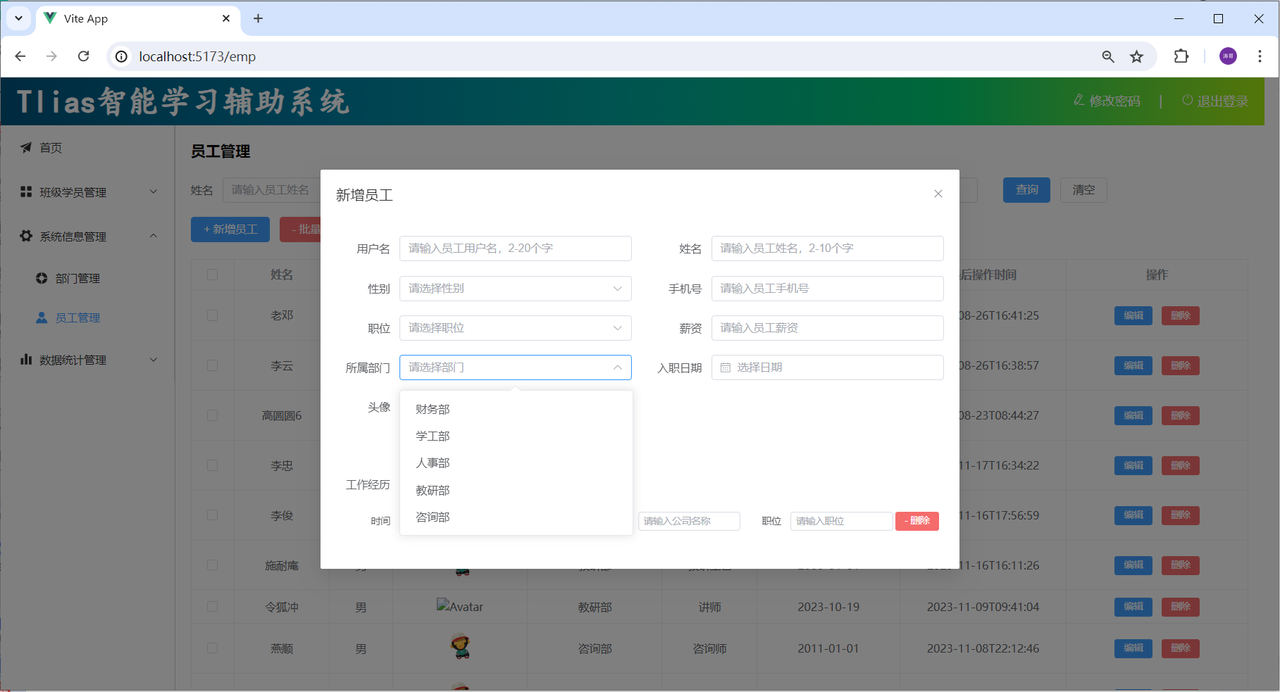

#### 添加/删除工作经历

> **补充｜动态表单行。** 用数组保存工作经历，每次添加一个全新的对象，删除时按索引操作。至少保留一行时禁用第一行删除按钮，并给每一行稳定的 `key`，避免输入值错位。

##### 需求

> **补充｜数据边界。** 员工基本信息和工作经历是一个整体提交，字段命名、日期格式和必填约束必须与后端 DTO 保持一致。先列出最小可提交数据，再逐项增加可选字段。

新增员工的基本信息表单已经制作完成了，那接下来，要制作的是员工的工作经历。

点击 "添加工作经历"  按钮后，新添加一条工作经历；点击每一条后面的 "删除" 按钮，需要删除当前工作经历。

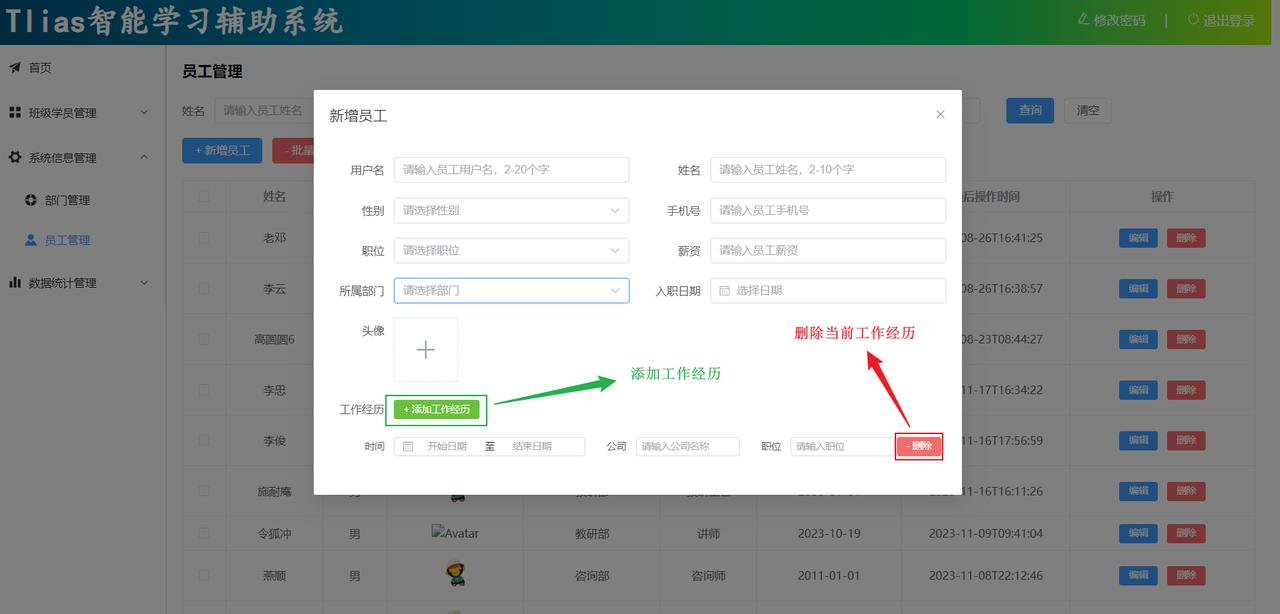

员工的过往工作经历可能是多条，点击 "添加员工工作经历" 按钮，如何增加一个条目 ？ 点击每一条后面的删除按钮，需要删除当前条件？

- Vue是基于数据驱动视图展示的。

- "添加" 时，我们可以往数组中添加数据。

- "删除" 时，可以删除数组中的元素。

- 一旦数据发生变化，视图中的展示就会发生变化。

##### 实现

1). 在 src/views/emp/index.vue 中的 <script> </script> 中增加如下代码：

```javascript
//工作经历
//动态添加工作经历 .
const addExprItem = () => {
  employee.value.exprList.push({exprDate: [], begin: '', end: '', company: '', job: ''})
}

//动态删除工作经历 .
const delExprItem = (index) => {
  employee.value.exprList.splice(index, 1)
}

//监听-employee员工对象中的工作经历数据
watch(()=>employee.value.exprList, (newValue, oldValue) => {
  if(employee.value.exprList && employee.value.exprList.length > 0) {
    employee.value.exprList.forEach(expr => {
      expr.begin = expr.exprDate[0]
      expr.end = expr.exprDate[1]
    })
  }
}, {deep: true});
```

2). 在 src/views/emp/index.vue 中的 <template> </template> 中的按钮绑定事件，并遍历展示工作经历信息：

```html
<!-- 新增/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
      <el-form ref="employeeFormRef" :model="employee" label-width="80px">
        <!-- 基本信息 -->
        <!-- 第一行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="用户名">
              <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
            </el-form-item>
          </el-col>
          
          <el-col :span="12">
            <el-form-item label="姓名">
              <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第二行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="性别">
              <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
                <el-option v-for="gender in genders" :key="gender.name" :label="gender.name" :value="gender.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>

          <el-col :span="12">
            <el-form-item label="手机号">
              <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第三行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="职位">
              <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
                <el-option v-for="job in jobs" :key="job.name" :label="job.name" :value="job.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="薪资">
              <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第四行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="所属部门">
              <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
                <el-option v-for="dept in deptList" :key="dept.id" :label="dept.name" :value="dept.id"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="入职日期">
              <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
        

        <!-- 工作经历 -->
        <!-- 第六行 -->
        <el-row :gutter="10">
          <el-col :span="24">
            <el-form-item label="工作经历">
              <el-button type="success" size="small" @click="addExprItem">+ 添加工作经历</el-button>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第七行 ...  工作经历 -->
        <el-row :gutter="3" v-for="(expr, index) in employee.exprList">
          <el-col :span="10">
            <el-form-item size="small" label="时间" label-width="80px">
              <el-date-picker type="daterange" v-model="expr.exprDate" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="公司" label-width="60px">
              <el-input placeholder="请输入公司名称" v-model="expr.company"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="职位" label-width="60px">
              <el-input placeholder="请输入职位" v-model="expr.job"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="2">
            <el-form-item size="small" label-width="0px">
              <el-button type="danger" @click="delExprItem(index)">- 删除</el-button>
            </el-form-item>
          </el-col>
        </el-row>
       </el-form>
       
        <!-- 底部按钮 -->
        <template #footer>
          <span class="dialog-footer">
            <el-button @click="dialogVisible = false">取消</el-button>
            <el-button type="primary" @click="">保存</el-button>
          </span>
        </template>

    </el-dialog>
```

到目前为止，src/views/emp/index.vue 页面的内容如下所示：

```html
<script setup>
import { ref, watch, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryPageApi } from '@/api/emp'
import { queryAllApi as queryAllDeptApi } from '@/api/dept'

//职位列表数据
const jobs = ref([{ name: '班主任', value: 1 },{ name: '讲师', value: 2 },{ name: '学工主管', value: 3 },{ name: '教研主管', value: 4 },{ name: '咨询师', value: 5 },{ name: '其他', value: 6 }])
//性别列表数据
const genders = ref([{ name: '男', value: 1 }, { name: '女', value: 2 }])
//部门列表数据
const deptList = ref([])

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

onMounted(async () => {
  search()

  //加载所有部门数据
  const result = await queryAllDeptApi();
  if(result.code){
    deptList.value = result.data
  }
})

//查询员工
const search= async () => {
  console.log('Search:', searchEmp.value)
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender, searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows
    total.value = result.data.total
  }
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)


// 分页处理
const handleSizeChange = (val) => {
  search()
}
const handleCurrentChange = (val) => {
  search()
}


//新增员工
const addEmp = () => {
  dialogVisible.value = true
  dialogTitle.value = '新增员工'
}

//新增/修改表单
const employeeFormRef = ref(null)
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

//文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response,uploadFile) => {
  employee.value.image = response.data
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

//工作经历
//动态添加工作经历 .
const addExprItem = () => {
  employee.value.exprList.push({exprDate: [], begin: '', end: '', company: '', job: ''})
}

//动态删除工作经历 .
const delExprItem = (index) => {
  employee.value.exprList.splice(index, 1)
}

//监听-employee员工对象中的工作经历数据
watch(()=>employee.value.exprList, (newValue, oldValue) => {
  if(employee.value.exprList && employee.value.exprList.length > 0) {
    employee.value.exprList.forEach(expr => {
      expr.begin = expr.exprDate[0]
      expr.end = expr.exprDate[1]
    })
  }
}, {deep: true});
</script>

<template>
  <h1>员工管理</h1> <br>
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click="addEmp"> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

  <!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="80" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" alt="Avatar" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
      <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
  <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />

  <!-- 新增/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
      <el-form ref="employeeFormRef" :model="employee" label-width="80px">
        <!-- 基本信息 -->
        <!-- 第一行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="用户名">
              <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
            </el-form-item>
          </el-col>
          
          <el-col :span="12">
            <el-form-item label="姓名">
              <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第二行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="性别">
              <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
                <el-option v-for="gender in genders" :key="gender.name" :label="gender.name" :value="gender.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>

          <el-col :span="12">
            <el-form-item label="手机号">
              <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第三行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="职位">
              <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
                <el-option v-for="job in jobs" :key="job.name" :label="job.name" :value="job.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="薪资">
              <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第四行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="所属部门">
              <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
                <el-option v-for="dept in deptList" :key="dept.id" :label="dept.name" :value="dept.id"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="入职日期">
              <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
        

        <!-- 工作经历 -->
        <!-- 第六行 -->
        <el-row :gutter="10">
          <el-col :span="24">
            <el-form-item label="工作经历">
              <el-button type="success" size="small" @click="addExprItem">+ 添加工作经历</el-button>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第七行 ...  工作经历 -->
        <el-row :gutter="3" v-for="(expr, index) in employee.exprList">
          <el-col :span="10">
            <el-form-item size="small" label="时间" label-width="80px">
              <el-date-picker type="daterange" v-model="expr.exprDate" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="公司" label-width="60px">
              <el-input placeholder="请输入公司名称" v-model="expr.company"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="职位" label-width="60px">
              <el-input placeholder="请输入职位" v-model="expr.job"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="2">
            <el-form-item size="small" label-width="0px">
              <el-button type="danger" @click="delExprItem(index)">- 删除</el-button>
            </el-form-item>
          </el-col>
        </el-row>
       </el-form>
       
        <!-- 底部按钮 -->
        <template #footer>
          <span class="dialog-footer">
            <el-button @click="dialogVisible = false">取消</el-button>
            <el-button type="primary" @click="">保存</el-button>
          </span>
        </template>

    </el-dialog>

</template>

<style scoped>
.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

接下来，我们就可以打开浏览器看到具体的页面效果了。

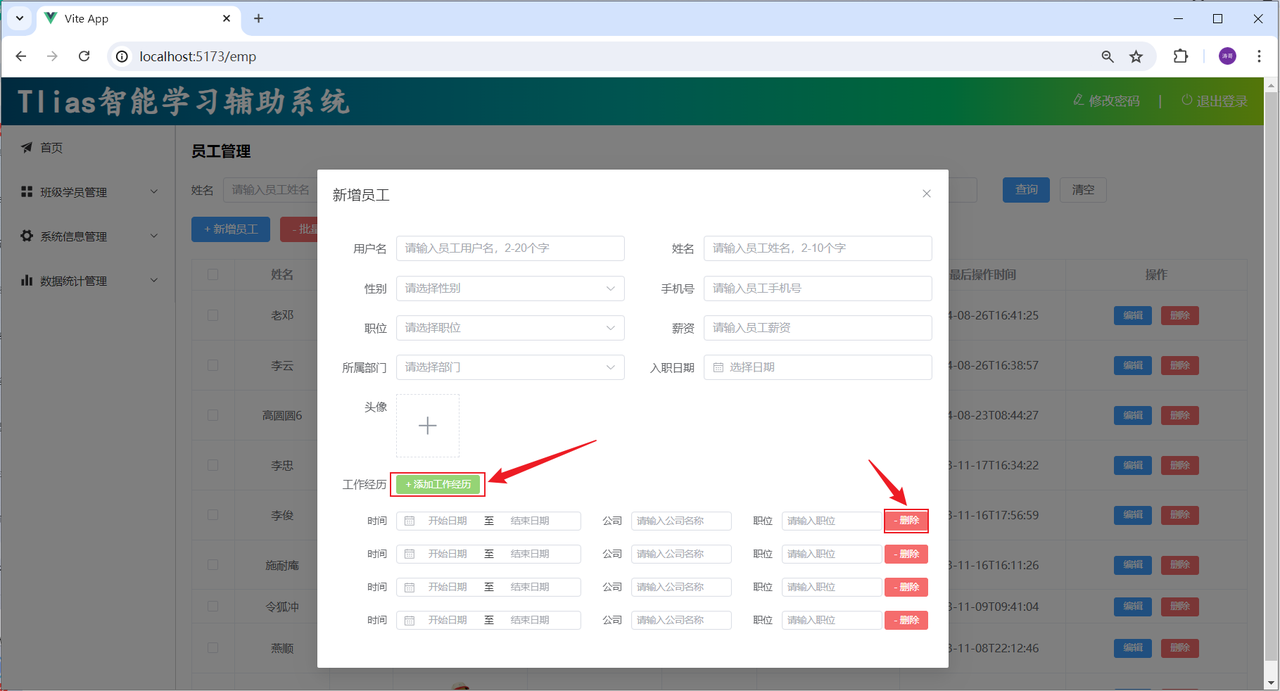

### 页面交互

> **补充｜状态反馈。** 查询、提交和弹窗关闭都要有明确的 loading、成功和失败状态。请求进行时禁用触发按钮，避免快速点击产生重复请求。

#### 保存员工信息

> **补充｜提交顺序。** 先调用表单 `validate()`，通过后再组装请求体并发送 POST。成功时提示、关闭弹窗、重置表单并刷新列表；失败时保留用户输入，方便修正。

基本的页面布局，我们完成之后，接下来，就需要完成页面的交互操作。 当点击 “保存”  按钮，需要执行如下操作：

1. 点击保存之后，发送异步请求到服务端，提交数据。

1. 保存完毕之后，如果成功，关闭对话框，重新加载列表数据。

1. 保存完毕之后，如果失败，提示错误信息。

具体操作如下：

1). 为 "保存"  按钮绑定事件

```html
        <!-- ........ 前面的代码省略了......... -->
        <!-- 底部按钮 -->
        <template #footer>
          <span class="dialog-footer">
            <el-button @click="dialogVisible = false">取消</el-button>
            <el-button type="primary" @click="save">保存</el-button>
          </span>
        </template>
    </el-dialog>
```

2). 在 <script></script> 中定义函数 save

```javascript
//保存员工信息
const save = async () => {
  const result = await addApi(employee.value);
  if(result.code){
    ElMessage.success('新增员工成功')
    dialogVisible.value = false
    search()
  }else {
    ElMessage.error(result.msg)
  }
}
```

然后我们就可以打开浏览器，测试添加员工了。

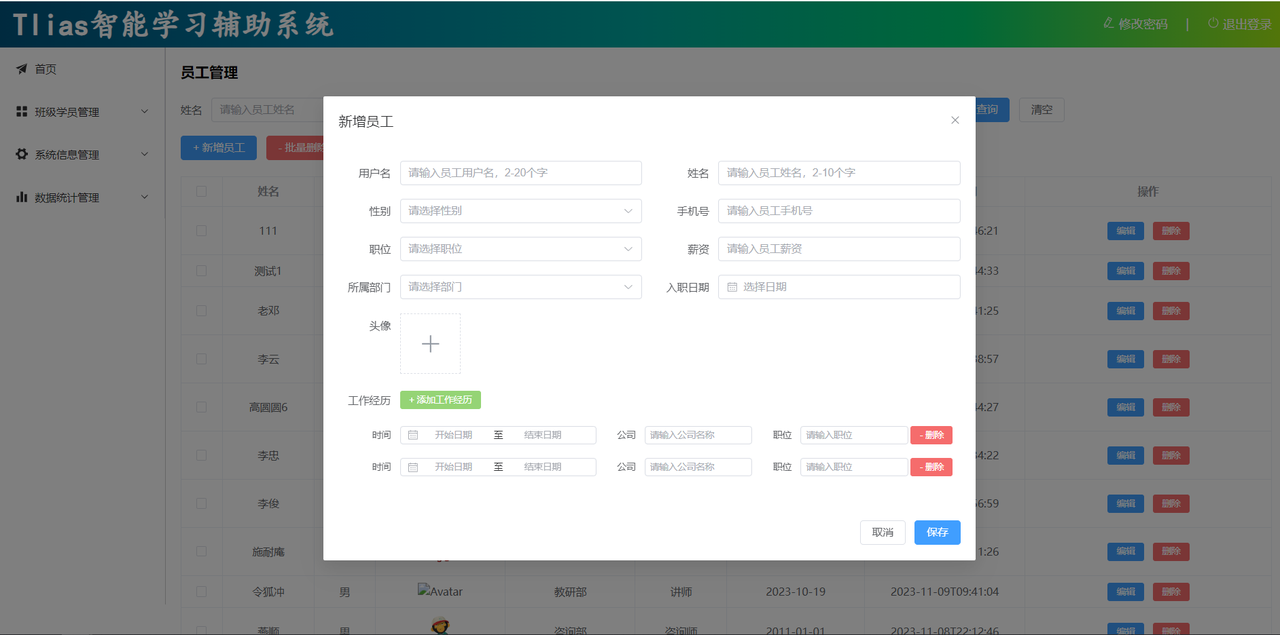

#### 表单校验

> **补充｜校验闭环。** `el-form` 的 `model`、`rules` 和每个控件的 `prop` 必须对应；除了必填项，还应校验手机号、日期范围和工作经历的起止日期。接口校验失败仍要展示后端返回的业务原因。

从页面原型中的需求描述，我们就可以提取出这个表单的校验规则。 我们可以打开页面原型来看一下：

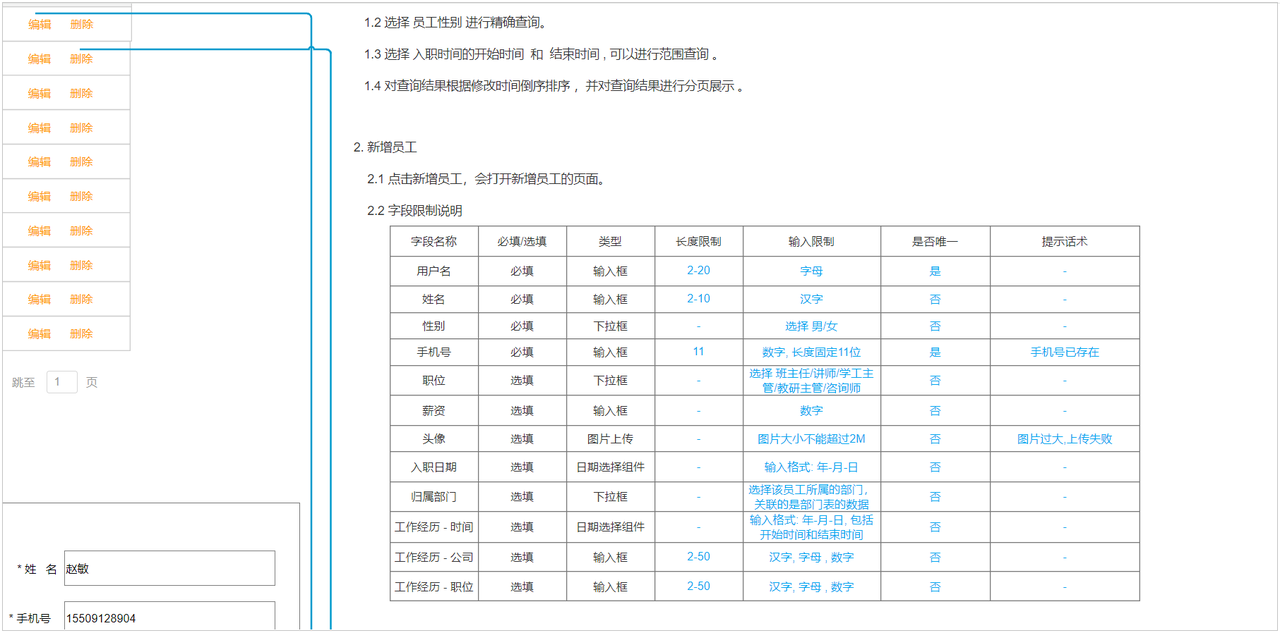

通过页面原型，我们可以提取到的校验规则如下：

表单校验规则：

- 用户名：必填，长度2-20

- 姓名：必填，长度2-10

- 性别：必填

- 手机号：必填，符合手机号规则

接下来，我们可以借助于AI，帮我们生成对应的校验规则：

**讲义提示**

> AI提示词(prompt):

> 请帮我生成ElementPlus中表单的校验规则，具体规则如下：

> 1. 用户名: 必填, 长度2-20

> 1. 姓名: 必填, 长度2-10

> 1. 性别: 必填

> 1. 手机号: 必填, 11位, 符合手机号规则

> 请帮我生成表单的校验规则, 并为表单项绑定对应的校验规则。

参考AI生成的代码，并在其基础上进行改造完成新增员工表单的校验。最终代码形式如下(新增代码为绿色背景)：

```html
<script setup>
import { ref, watch, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryPageApi, addApi } from '@/api/emp'
import { queryAllApi as queryAllDeptApi } from '@/api/dept'

//职位列表数据
const jobs = ref([{ name: '班主任', value: 1 },{ name: '讲师', value: 2 },{ name: '学工主管', value: 3 },{ name: '教研主管', value: 4 },{ name: '咨询师', value: 5 },{ name: '其他', value: 6 }])
//性别列表数据
const genders = ref([{ name: '男', value: 1 }, { name: '女', value: 2 }])
//部门列表数据
const deptList = ref([])

const searchEmp = ref({
  name: '',
  gender: '',
  date: [],
  begin: '',
  end: ''
})

//侦听searchEmp中的date属性
watch(
  () => searchEmp.value.date,
  (newValue, oldValue) => {
     if(newValue.length == 2){
      searchEmp.value.begin = newValue[0]
      searchEmp.value.end = newValue[1]
     }else {
      searchEmp.value.begin = ''
      searchEmp.value.end = ''
     }
  }
)

onMounted(async () => {
  search()

  //加载所有部门数据
  const result = await queryAllDeptApi();
  if(result.code){
    deptList.value = result.data
  }
})

//查询员工
const search = async () => {
  console.log('Search:', searchEmp.value)
  const result = await queryPageApi(searchEmp.value.name, searchEmp.value.gender, searchEmp.value.begin, searchEmp.value.end, currentPage.value, pageSize.value);
  if(result.code){
    empList.value = result.data.rows
    total.value = result.data.total
  }
}

const clear = () => {
  // 清空表单
  searchEmp.value = {
    name: '',
    gender: '',
    date: [],
    begin: '',
    end: ''
  }
  search()
}

// 示例数据
const empList = ref([])

// 分页配置
const currentPage = ref(1)
const pageSize = ref(10)
const total = ref(0)

// 分页处理
const handleSizeChange = (val) => {
  search()
}
const handleCurrentChange = (val) => {
  search()
}


//新增/修改表单
const employeeFormRef = ref(null)
const employee = ref({
  username: '',
  name: '',
  gender: '',
  phone: '',
  job: '',
  salary: '',
  deptId: '',
  entryDate: '',
  image: '',
  exprList: []
})

//新增员工
const addEmp = () => {
  dialogVisible.value = true
  dialogTitle.value = '新增员工'
  
  //清空表单内容及校验提示信息
  employee.value = {
    username: '',
    name: '',
    gender: '',
    phone: '',
    job: '',
    salary: '',
    deptId: '',
    entryDate: '',
    image: '',
    exprList: []
  }
  if(employeeFormRef.value){
      employeeFormRef.value.resetFields()
  }
}

//表单校验规则
// 验证规则
const rules = ref({
  username: [
    { required: true, message: '请输入用户名', trigger: 'blur' },
    { min: 2, max: 20, message: '用户名长度应在2到20个字符之间', trigger: 'blur' }
  ],
  name: [
    { required: true, message: '请输入姓名', trigger: 'blur' },
    { min: 2, max: 10, message: '姓名长度应在2到10个字符之间', trigger: 'blur' }
  ],
  gender: [
    { required: true, message: '请选择性别', trigger: 'change' }
  ],
  phone: [
    { required: true, message: '请输入手机号', trigger: 'blur' },
    { pattern: /^1\d{10}$/g, message: '请输入有效的手机号', trigger: 'blur' }
  ]
});

// 控制弹窗
const dialogVisible = ref(false)
const dialogTitle = ref('新增员工')

//文件上传
// 图片上传成功后触发
const handleAvatarSuccess = (response,uploadFile) => {
  employee.value.image = response.data
}
// 文件上传之前触发
const beforeAvatarUpload = (rawFile) => {
  if (rawFile.type !== 'image/jpeg' && rawFile.type !== 'image/png') {
    ElMessage.error('只支持上传图片')
    return false
  } else if (rawFile.size / 1024 / 1024 > 10) {
    ElMessage.error('只能上传10M以内图片')
    return false
  }
  return true
}

//工作经历
//动态添加工作经历 .
const addExprItem = () => {
  employee.value.exprList.push({exprDate: [], begin: '', end: '', company: '', job: ''})
}

//动态删除工作经历 .
const delExprItem = (index) => {
  employee.value.exprList.splice(index, 1)
}

//监听-employee员工对象中的工作经历数据
watch(employee, (newVal, oldVal) => {
  if(employee.value.exprList) {
    employee.value.exprList.forEach(expr => {
      expr.begin = expr.exprDate[0]
      expr.end = expr.exprDate[1]
    })
  }
}, {deep: true})

//保存员工信息
const save = async () => {
  employeeFormRef.value.validate(async valid => {
    if(valid){ // 校验通过
      const result = await addApi(employee.value);
      if(result.code){
        ElMessage.success('新增员工成功')
        dialogVisible.value = false
        search()
      }else {
        ElMessage.error(result.msg)
      }
    }
  })
}
</script>

<template>
  <h1>员工管理</h1> <br>
  <el-form :inline="true" :model="searchEmp">
    <el-form-item label="姓名">
      <el-input v-model="searchEmp.name" placeholder="请输入员工姓名"></el-input>
    </el-form-item>

    <el-form-item label="性别">
      <el-select v-model="searchEmp.gender" placeholder="请选择">
        <el-option label="男" value="1"></el-option>
        <el-option label="女" value="2"></el-option>
      </el-select>
    </el-form-item>

    <el-form-item label="入职日期">
      <el-date-picker
        v-model="searchEmp.date"
        type="daterange"
        range-separator="至"
        start-placeholder="开始日期"
        end-placeholder="结束日期"
        value-format="YYYY-MM-DD"
      ></el-date-picker>
    </el-form-item>

    <el-form-item>
      <el-button type="primary" @click="search">查询</el-button>
      <el-button @click="clear">清空</el-button>
    </el-form-item>
  </el-form>

  <el-button type="primary" @click="addEmp"> + 新增员工</el-button>
  <el-button type="danger" @click=""> - 批量删除</el-button>
  <br><br>

  <!-- 表格 -->
  <el-table :data="empList" border style="width: 100%">
    <el-table-column type="selection" width="55" align="center"></el-table-column>
    <el-table-column prop="name" label="姓名" width="120" align="center"></el-table-column>
    <el-table-column label="性别" width="80" align="center">
      <template #default="scope" >
        {{ scope.row.gender == 1 ? '男' : '女' }}
      </template>
    </el-table-column>
    <el-table-column label="头像" width="170" align="center">
      <template #default="scope" >
        <img :src="scope.row.image" alt="Avatar" class="avatar" />
      </template>
    </el-table-column>
    <el-table-column prop="deptName" label="部门名称" width="170" align="center"></el-table-column>
    <el-table-column label="职位" width="120" align="center">
      <template #default="scope">
          <span v-if="scope.row.job == 1">班主任</span>
          <span v-else-if="scope.row.job == 2">讲师</span>
          <span v-else-if="scope.row.job == 3">学工主管</span>
          <span v-else-if="scope.row.job == 4">教研主管</span>
          <span v-else-if="scope.row.job == 5">咨询师</span>
          <span v-else>其他</span>
        </template>
    </el-table-column>
    <el-table-column prop="entryDate" label="入职日期" width="180" align="center"></el-table-column>
    <el-table-column prop="updateTime" label="最后操作时间" width="210" align="center"></el-table-column>
    <el-table-column label="操作" fixed="right" align="center">
      <template #default="scope">
        <el-button size="small" type="primary" @click="">编辑</el-button>
        <el-button size="small" type="danger" @click="">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <br>

  <!-- 分页 -->
    <el-pagination
      v-model:current-page="currentPage"
      v-model:page-size="pageSize"
      :page-sizes="[5, 10, 20, 30, 50, 75, 100]"
      :background="background"
      layout="total, sizes, prev, pager, next, jumper"
      :total="total"
      @size-change="handleSizeChange"
      @current-change="handleCurrentChange"
    />

  <!-- 新增/修改员工的对话框 -->
  <el-dialog v-model="dialogVisible" :title="dialogTitle">
      <el-form ref="employeeFormRef" :model="employee" :rules="rules" label-width="80px">
        <!-- 基本信息 -->
        <!-- 第一行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="用户名" prop="username">
              <el-input v-model="employee.username" placeholder="请输入员工用户名，2-20个字"></el-input>
            </el-form-item>
          </el-col>
          
          <el-col :span="12">
            <el-form-item label="姓名" prop="name">
              <el-input v-model="employee.name" placeholder="请输入员工姓名，2-10个字"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第二行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="性别" prop="gender">
              <el-select v-model="employee.gender" placeholder="请选择性别" style="width: 100%;">
                <el-option v-for="gender in genders" :key="gender.name" :label="gender.name" :value="gender.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>

          <el-col :span="12">
            <el-form-item label="手机号" prop="phone">
              <el-input v-model="employee.phone" placeholder="请输入员工手机号"></el-input>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第三行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="职位">
              <el-select v-model="employee.job" placeholder="请选择职位" style="width: 100%;">
                <el-option v-for="job in jobs" :key="job.name" :label="job.name" :value="job.value"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="薪资">
              <el-input v-model="employee.salary" placeholder="请输入员工薪资"></el-input>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第四行 -->
        <el-row :gutter="20">
          <el-col :span="12">
            <el-form-item label="所属部门">
              <el-select v-model="employee.deptId" placeholder="请选择部门" style="width: 100%;">
                <el-option v-for="dept in deptList" :key="dept.id" :label="dept.name" :value="dept.id"></el-option>
              </el-select>
            </el-form-item>
          </el-col>
          <el-col :span="12">
            <el-form-item label="入职日期">
              <el-date-picker v-model="employee.entryDate" type="date" style="width: 100%;" placeholder="选择日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD"></el-date-picker>
            </el-form-item>
          </el-col>
        </el-row>

        <!-- 第五行 -->
        <el-row :gutter="20">
          <el-col :span="24">
            <el-form-item label="头像">
              <el-upload
                class="avatar-uploader"
                action="/api/upload"
                :show-file-list="false"
                :on-success="handleAvatarSuccess"
                :before-upload="beforeAvatarUpload"
                >
                <img v-if="employee.image" :src="employee.image" class="avatar" />
                <el-icon v-else class="avatar-uploader-icon"><Plus /></el-icon>
              </el-upload>
            </el-form-item>
          </el-col>
        </el-row>
        

        <!-- 工作经历 -->
        <!-- 第六行 -->
        <el-row :gutter="10">
          <el-col :span="24">
            <el-form-item label="工作经历">
              <el-button type="success" size="small" @click="addExprItem">+ 添加工作经历</el-button>
            </el-form-item>
          </el-col>
        </el-row>
        
        <!-- 第七行 ...  工作经历 -->
        <el-row :gutter="3" v-for="(expr, index) in employee.exprList">
          <el-col :span="10">
            <el-form-item size="small" label="时间" label-width="80px">
              <el-date-picker type="daterange" v-model="expr.exprDate" range-separator="至" start-placeholder="开始日期" end-placeholder="结束日期" format="YYYY-MM-DD" value-format="YYYY-MM-DD" ></el-date-picker>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="公司" label-width="60px">
              <el-input placeholder="请输入公司名称" v-model="expr.company"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="6">
            <el-form-item size="small" label="职位" label-width="60px">
              <el-input placeholder="请输入职位" v-model="expr.job"></el-input>
            </el-form-item>
          </el-col>

          <el-col :span="2">
            <el-form-item size="small" label-width="0px">
              <el-button type="danger" @click="delExprItem(index)">- 删除</el-button>
            </el-form-item>
          </el-col>
        </el-row>
      </el-form>

      <!-- 底部按钮 -->
      <template #footer>
        <span class="dialog-footer">
          <el-button @click="dialogVisible = false">取消</el-button>
          <el-button type="primary" @click="save">保存</el-button>
        </span>
      </template>
    </el-dialog>

</template>

<style scoped>
.avatar {
  height: 40px;
}
.avatar-uploader .avatar {
  width: 78px;
  height: 78px;
  display: block;
}
.avatar-uploader .el-upload {
  border: 1px dashed var(--el-border-color);
  border-radius: 6px;
  cursor: pointer;
  position: relative;
  overflow: hidden;
  transition: var(--el-transition-duration-fast);
}

.avatar-uploader .el-upload:hover {
  border-color: var(--el-color-primary);
}

.el-icon.avatar-uploader-icon {
  font-size: 28px;
  color: #8c939d;
  width: 78px;
  height: 78px;
  text-align: center;
  /* 添加灰色的虚线边框 */
  border: 1px dashed var(--el-border-color);
}
</style>
```

代码编写完毕后，我们可以打开浏览器测试一下。

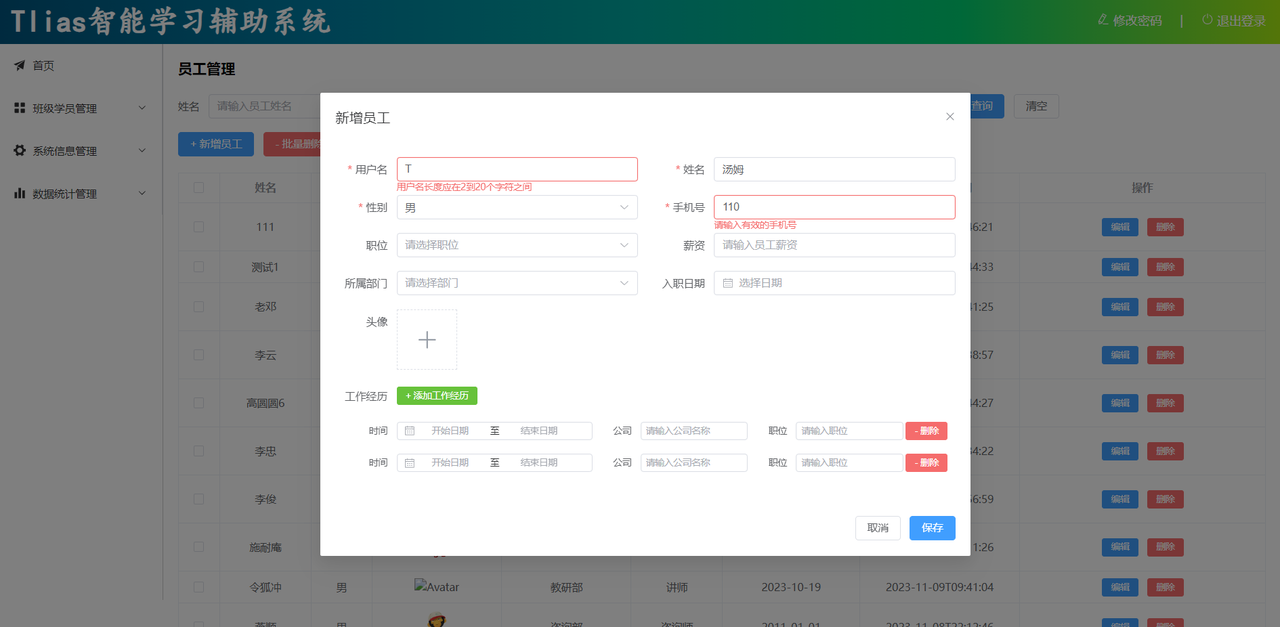

我们可以看到，我们为表单添加的校验规则，确实生效了。 并且，如果表单校验不通过，是不能保存员工信息的。

## 复习速查与验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 条件分页 | 筛选条件、页码、页大小一起提交 | 改变条件后仍停留在旧页码 |
| 搜索表单 | 姓名、性别和日期范围映射为接口参数 | 清空控件后仍提交旧值 |
| `watch` 侦听 | 统一响应条件或分页变化并重新查询 | 初始化和用户操作触发重复请求 |
| 表格展示 | 格式化显示字段，不改写原始数据 | 把分页响应对象直接遍历 |
| Dialog 表单 | 打开初始化，关闭清理，提交前校验 | 上一次员工信息残留到下一次新增 |
| 动态工作经历 | 数组增删与后端字段结构保持一致 | 删除最后一行导致表单无法继续填写 |
| ElementPlus 校验 | `el-form` 配合 `rules`、`prop` 和 `validate()` | 只写 rules 却没有绑定 prop |
| 异步提交 | 成功提示、关闭弹窗、刷新列表形成闭环 | 请求失败仍清空用户输入 |

### 跟练验收

1. 员工列表首次进入时显示加载状态，查询完成后正确展示表格、总条数和分页器。
2. 按姓名、性别和日期范围查询，确认参数正确，且每次新条件都会回到第 1 页。
3. 切换页码和页大小，确认请求参数变化且列表数据与分页状态同步。
4. 清空搜索条件或接口返回空数组时，页面能显示空状态而不是旧数据。
5. 打开新增员工弹窗，填写基本信息并动态添加、删除工作经历，确认数组数据正确。
6. 空表单和非法日期不能提交；所有必填项通过后才发送新增请求。
7. 新增成功后弹窗关闭、表单重置、列表刷新，总条数和新员工信息正确。
8. 连续快速点击搜索和提交按钮，确认不会产生重复请求或重复提示。
9. 用浏览器 Network 面板核对请求方法、URL、查询参数、请求体和响应结构。

### 自测问题

- 条件分页查询为什么要把筛选条件、页码和页大小统一管理？
- `watch` 侦听查询条件时，为什么通常要把页码重置为 1？
- 日期范围控件的值如何转换为接口需要的开始日期和结束日期？
- 动态工作经历表单为什么要为每行创建独立对象并设置稳定 key？
- `el-form` 的 `model`、`rules`、`prop` 和 `validate()` 如何配合？
- 新增请求成功后为什么要重新查询列表，而不是只把新对象 push 到本地数组？